In [1]:
# Permite importar src/ desde la carpeta notebooks/
import sys
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src.config import DIR_DATA_RAW

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid")

In [2]:
from src.faenas import cargar_faenas, construir_viajes, unir_solapados
from src.telemetria import asignar_viaje, cruzar_nombres

viajes, calas, obs = construir_viajes(cargar_faenas(DIR_DATA_RAW / "faenas" / "pod.csv"))
viajes, calas = unir_solapados(viajes, calas)
display(obs)

tel = pd.concat([pd.read_parquet(a) for a in (DIR_DATA_RAW / "telemetria").glob("*.parquet")])
tel["fecha"] = pd.to_datetime(tel["fecha"])

# 1. ¿Los nombres coinciden entre telemetría y faenas?
nombres = cruzar_nombres(tel, viajes)
display(nombres[~(nombres.en_telemetria & nombres.en_faenas)])

# 2. Asignar viaje
tel_v = asignar_viaje(tel, viajes)
print(f"Registros con viaje: {tel_v['IdViaje'].notna().mean():.1%}")
display(tel_v.groupby("ep")["IdViaje"].apply(lambda s: s.notna().mean()).sort_values().to_frame("% con viaje"))

# 3. ¿Cada cuánto llega un registro de telemetría?
print(tel_v.groupby("ep")["fecha"].diff().dt.total_seconds().div(60).describe(percentiles=[.5, .9, .99]))

,observacion,filas
0,zarpe con año futuro (descartadas),2
1,registros unidos al mismo viaje,1049
2,zarpe posterior a la 1ra cala (corregido -1 día),26
3,"viajes inválidos (sin fin, duración fuera de 0...",54


,embarcacion,en_telemetria,en_faenas
1,ANTARES III,False,True
2,AREQUIPA 5,False,True
6,CLAUDIA,False,True
7,CORINTIA,False,True
8,COSTA BRAVA,False,True
12,DON VICTOR,False,True
13,DORADO,False,True
15,GUANAY,False,True
16,IPANEMA,False,True
17,JUNIN 2,False,True


Registros con viaje: 56.8%


,% con viaje
ep,
SANTA ADELA II,0.33
MARY,0.34
POLAR I,0.40
DON ALFREDO,0.49
CUZCO 4,0.50
CRETA,0.56
RODAS,0.56
BLANDI,0.58
CARMENCITA,0.59


count   198,583.00
mean         58.64
std       1,782.31
min           0.00
50%          15.00
90%          15.23
99%         150.03
max     205,570.18
Name: fecha, dtype: float64


Duplicados eliminados: 3
Registros fuera del periodo de faenas: 7.9%
% con viaje (dentro del periodo): 61.7%


,Velocidad,rpm,gal_h
min_rel,,,
-120.00,7.80,877.00,33.70
-105.00,6.60,849.00,29.26
-90.00,4.00,719.00,20.20
-75.00,1.00,687.00,16.70
-60.00,0.60,679.00,15.20
-45.00,0.50,675.00,13.60
-30.00,0.60,672.00,12.42
-15.00,0.70,658.00,10.90
-0.00,1.55,657.00,12.90


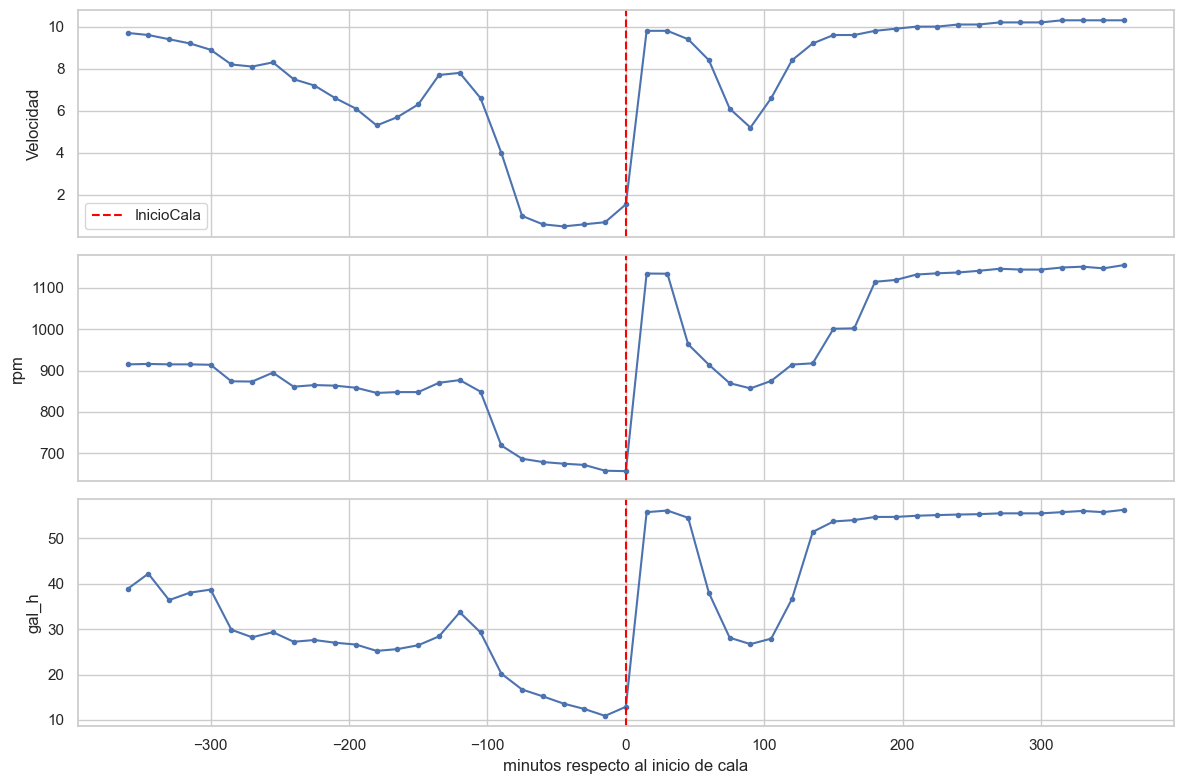

In [3]:
# 1. Quitar duplicados (misma embarcación y misma hora)
tel["ep"] = tel["ep"].astype(str).str.strip().str.upper()
antes = len(tel)
tel = tel.drop_duplicates(subset=["ep", "fecha"]).sort_values(["ep", "fecha"])
print(f"Duplicados eliminados: {antes - len(tel):,}")

# 2. % con viaje SOLO dentro de los meses que tienen faenas
tel_v = asignar_viaje(tel, viajes)
meses_faenas = set(viajes["ZarpeCorregido"].dt.to_period("M"))
dentro = tel_v["fecha"].dt.to_period("M").isin(meses_faenas)
print(f"Registros fuera del periodo de faenas: {(~dentro).mean():.1%}")
print(f"% con viaje (dentro del periodo): {tel_v.loc[dentro, 'IdViaje'].notna().mean():.1%}")

# 3. Velocidad y RPM alrededor de cada inicio de cala (en bloques de 15 min)
c = calas.merge(viajes[["IdViaje", "Embarcacion"]], on="IdViaje")
c = c[c["Embarcacion"].isin(tel["ep"].unique())]

filas = []
for ep, grupo in c.groupby("Embarcacion"):
    t = tel[tel["ep"] == ep][["fecha", "Velocidad", "rpm", "gal_h"]]
    for inicio in grupo["InicioCala"]:
        w = t[t["fecha"].between(inicio - pd.Timedelta(hours=6), inicio + pd.Timedelta(hours=6))].copy()
        w["min_rel"] = ((w["fecha"] - inicio).dt.total_seconds() / 60 / 15).round() * 15
        filas.append(w)

perfil = pd.concat(filas).groupby("min_rel")[["Velocidad", "rpm", "gal_h"]].median()

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, col in zip(axes, perfil.columns):
    ax.plot(perfil.index, perfil[col], marker="o", ms=3)
    ax.axvline(0, color="red", ls="--", label="InicioCala")
    ax.set_ylabel(col)
axes[0].legend()
axes[-1].set_xlabel("minutos respecto al inicio de cala")
plt.tight_layout()

display(perfil.loc[-120:240])

Calas detectadas: 79.5% de 2,989


,DuracionEstMin,DesfaseInicioMin,DesfaseFinMin
count,"2,377.00","2,377.00","2,377.00"
mean,70.22,-74.99,-4.77
std,30.22,30.86,11.70
min,0.00,-237.88,-44.83
5%,30.01,-121.84,-18.90
25%,59.73,-87.88,-11.85
50%,60.30,-72.88,-6.43
75%,75.43,-60.87,0.10
95%,119.99,-32.77,15.12
max,255.08,42.18,44.23


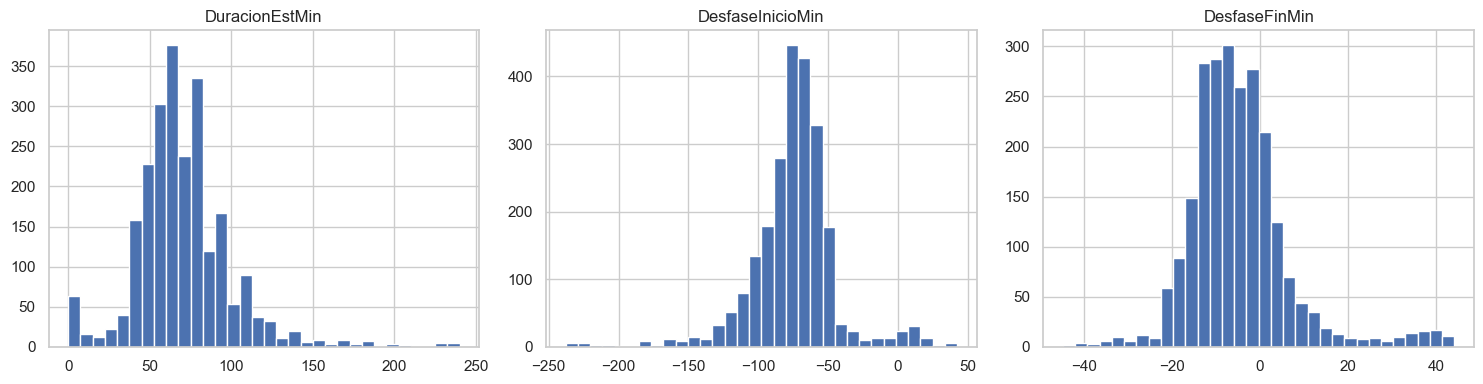

In [4]:
from src.calas import estimar_ventana_calas

v_ok = viajes[viajes["FuenteFin"] == "real"]
ventanas = estimar_ventana_calas(tel, calas[calas["IdViaje"].isin(v_ok["IdViaje"])], v_ok)

print(f"Calas detectadas: {ventanas['CalaDetectada'].mean():.1%} de {len(ventanas):,}")
display(ventanas[["DuracionEstMin", "DesfaseInicioMin", "DesfaseFinMin"]]
        .describe(percentiles=[.05, .25, .5, .75, .95]))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["DuracionEstMin", "DesfaseInicioMin", "DesfaseFinMin"]):
    ventanas[col].dropna().clip(-240, 240).hist(bins=32, ax=ax)
    ax.set_title(col)
plt.tight_layout()

,%
MetodoVentana,
telemetria,0.73
regla,0.21
fin_telemetria,0.05


,registros
Etiqueta,
sin_viaje,85787
busqueda,41245
retorno,27766
ida,20967
cala,13394
viaje_sin_cala,8651


,Velocidad,rpm,gal_h
Etiqueta,,,
busqueda,9.70,916.00,51.60
cala,0.60,673.00,12.68
ida,11.60,"1,204.00",57.86
retorno,10.80,"1,193.00",58.12
sin_viaje,9.70,902.00,47.80
viaje_sin_cala,10.80,"1,147.00",54.69


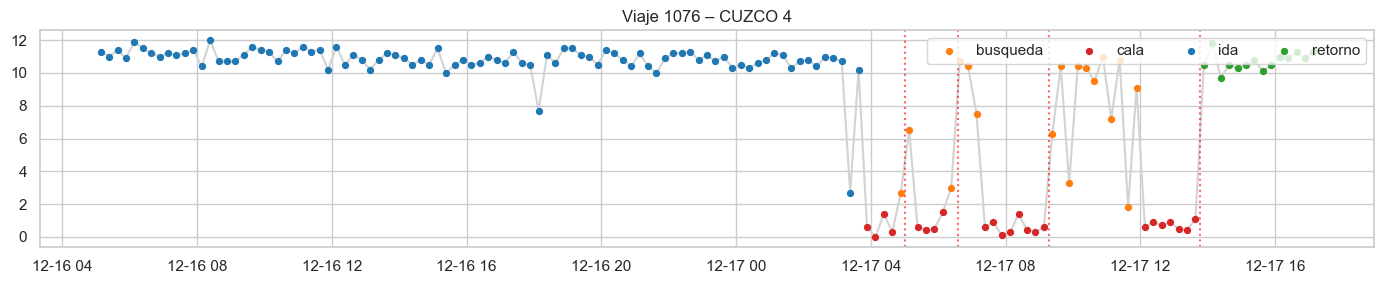

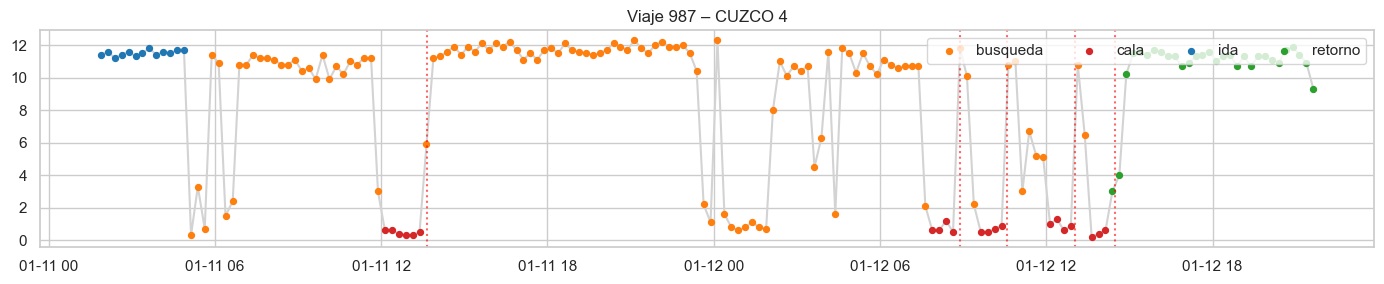

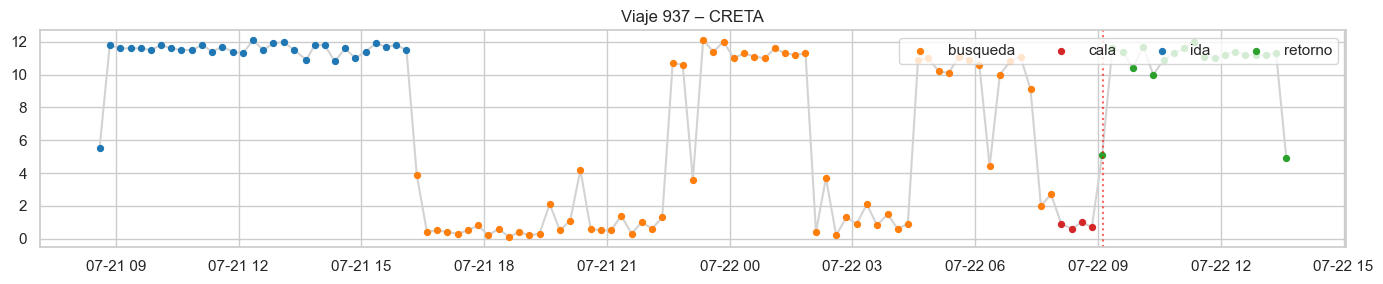

In [5]:
from src.etiquetas import ventanas_finales, etiquetar

vf = ventanas_finales(ventanas)
display(vf["MetodoVentana"].value_counts(normalize=True).to_frame("%"))

tel_e = etiquetar(tel_v[tel_v["IdViaje"].isna() | tel_v["IdViaje"].isin(v_ok["IdViaje"])], vf)
display(tel_e["Etiqueta"].value_counts().to_frame("registros"))
display(tel_e.groupby("Etiqueta")[["Velocidad", "rpm", "gal_h"]].median())

# Ver 3 viajes al azar: velocidad en el tiempo, coloreada por etiqueta
colores = {"ida": "tab:blue", "busqueda": "tab:orange", "cala": "tab:red", "retorno": "tab:green"}
for idv in tel_e.loc[tel_e["Etiqueta"] == "cala", "IdViaje"].drop_duplicates().sample(3, random_state=7):
    d = tel_e[tel_e["IdViaje"] == idv]
    fig, ax = plt.subplots(figsize=(14, 3))
    ax.plot(d["fecha"], d["Velocidad"], color="lightgray", zorder=1)
    for etq, g in d.groupby("Etiqueta"):
        ax.scatter(g["fecha"], g["Velocidad"], s=18, label=etq, color=colores.get(etq, "gray"), zorder=2)
    for _, c in calas[calas["IdViaje"] == idv].iterrows():
        ax.axvline(c["InicioCala"], color="red", ls=":", alpha=0.6)
    ax.set_title(f"Viaje {idv} – {d['ep'].iloc[0]}")
    ax.legend(loc="upper right", ncol=4)
    plt.tight_layout()

In [6]:
from src.rumbo import verificar_codigos_rumbo, agregar_variables_rumbo

display(verificar_codigos_rumbo(tel_v))

,rumbo_gps_medio,concentracion,n
Rumbo,,,
0,1.30,0.89,200.00
1,52.33,0.81,362.00
2,91.49,0.86,115.00
3,147.18,0.91,"1,416.00"
4,177.88,0.93,175.00
5,221.63,0.83,432.00
6,269.61,0.81,124.00
7,330.20,0.92,"1,386.00"
0,344.86,0.05,"4,870.00"


In [7]:
from src.rumbo import rumbo_gps

t = tel_v.sort_values(["ep", "fecha"]).copy()
t["tipo_rumbo"] = t["Rumbo"].map(lambda x: type(x).__name__)
g = t.groupby("ep")
lat0, lon0 = np.radians(g["Latitud"].shift()), np.radians(g["Longitud"].shift())
lat1, lon1 = np.radians(t["Latitud"]), np.radians(t["Longitud"])
a = np.sin((lat1 - lat0) / 2)**2 + np.cos(lat0) * np.cos(lat1) * np.sin((lon1 - lon0) / 2)**2
t["dist_km"] = 6371 * 2 * np.arcsin(np.sqrt(a))
t["dt_h"] = g["fecha"].diff().dt.total_seconds() / 3600
t["vel_gps"] = t["dist_km"] / 1.852 / t["dt_h"]          # nudos
t["misma_pos"] = t["dist_km"] < 0.01                      # no se movió (<10 m)

ok = t["dt_h"].between(0.1, 0.5) & (t["Velocidad"] >= 6)  # navegando, registros consecutivos
resumen = t[ok].groupby(["origen", "tipo_rumbo"]).agg(
    n=("Velocidad", "size"),
    vel_reportada=("Velocidad", "median"),
    vel_gps=("vel_gps", "median"),
    pct_misma_posicion=("misma_pos", "mean"),
)
display(resumen.round(2))

# Ejemplo crudo de una fuente histórica: ¿cómo lucen las coordenadas?
display(t[t["origen"] == "mp_m_h"][["ep", "fecha", "Latitud", "Longitud", "Velocidad", "Rumbo", "dist_km"]].head(15))

c:\Users\srios\AppData\Local\Programs\Python\Python314\Lib\site-packages\pandas\core\arraylike.py:399: RuntimeWarning: invalid value encountered in sqrt
  result = getattr(ufunc, method)(*inputs, **kwargs)


,,n,vel_reportada,vel_gps,pct_misma_posicion
origen,tipo_rumbo,,,,
mp_e,int,4204,11.30,11.15,0.00
mp_e_h,str,40377,11.40,"21,458.50",0.00
mp_m,str,6335,10.80,6.47,0.00
mp_m_h,str,72745,11.40,"21,484.86",0.00


,ep,fecha,Latitud,Longitud,Velocidad,Rumbo,dist_km
9030,BLANDI,2025-01-01 00:11:12,"-557,226.00","-4,720,970.00",11.70,5,NaN
9031,BLANDI,2025-01-01 00:26:09,"-559,945.00","-4,721,968.00",11.50,5,"13,574.23"
9032,BLANDI,2025-01-01 00:41:09,"-562,586.00","-4,723,170.00",11.10,5,"14,126.90"
9033,BLANDI,2025-01-01 00:56:09,"-565,358.00","-4,723,979.00",12.10,5,"12,439.81"
9034,BLANDI,2025-01-01 01:11:10,"-568,173.00","-4,724,813.00",11.70,4,"7,699.80"
9035,BLANDI,2025-01-01 01:26:06,"-571,002.00","-4,725,706.00",11.80,5,"5,006.38"
9036,BLANDI,2025-01-01 03:11:09,"-590,733.00","-4,731,741.00",11.80,5,"11,591.52"
9037,BLANDI,2025-01-01 03:26:10,"-593,557.00","-4,732,499.00",11.40,5,"6,402.21"
9038,BLANDI,2025-01-01 03:41:06,"-596,397.00","-4,733,056.00",11.40,4,"2,932.94"
9039,BLANDI,2025-01-01 03:56:07,"-599,240.00","-4,732,799.00",11.70,3,"8,908.11"
